# Problem 3: Autoregressive Models on the Binary Tokens from Problem 2

Each MNIST image was encoded by the Problem 2 autoencoder into a 3×4×4 grid of ±1 bits.
Here the 3 bits at each of the 4×4 positions are turned into one decimal token (0–7),
so every image becomes a **sequence of 16 tokens**. Three autoregressive models learn
p(Z) = ∏ p(zᵢ | z₍<ᵢ₎) and must generate sequences that are copies of training sequences:

| Part | Input → Output | Target |
|---|---|---|
| 3(a) | prefix → next token (GRU) | > 80% generated sequences in training set |
| 3(b) | sequence → sequence (Transformer, causal mask) | > 80% |
| 3(c) | prefix → histogram of next token (GRU) | > 99%, with > 512 images |

All three use the same **1024** images as Problem 2 (allowed, and needed for 3(c)).

**Before running:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all.
When asked, upload `binary_autoencoder.pt` from Problem 2. Total run time on a T4: about 5–10 minutes.

In [ ]:
import os, time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
NUM_TRAIN = 1024          # must match Problem 2
NUM_SAMPLES = 1000        # sequences generated per model
SEQ_LEN, VOCAB = 16, 8    # 16 positions, tokens 0..7
PAD = BOS = 8             # extra symbol for "empty" / "start"

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 1. Load the Problem 2 autoencoder and turn images into tokens

In [ ]:
# Same model definition as Problem 2 (needed to load the saved weights)
def binary_ste(x):
    hard = torch.where(x >= 0, torch.ones_like(x), -torch.ones_like(x))
    return x + (hard - x).detach()

def conv_block(c_in, c_out, k=3, stride=1, padding=1):
    return nn.Sequential(nn.Conv2d(c_in, c_out, k, stride=stride, padding=padding),
                         nn.BatchNorm2d(c_out), nn.ReLU())

class BinaryAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.binarize = True
        self.noise_std = 0.0
        self.encoder = nn.Sequential(
            conv_block(1, 64), conv_block(64, 128, 4, stride=2),
            conv_block(128, 256, 4, stride=2), conv_block(256, 256, 3, stride=2),
            nn.Conv2d(256, 3, kernel_size=1), nn.BatchNorm2d(3, affine=False))
        self.decoder = nn.Sequential(
            conv_block(3, 256), nn.Upsample(size=(7, 7), mode="bilinear", align_corners=False),
            conv_block(256, 256), nn.Upsample(size=(14, 14), mode="bilinear", align_corners=False),
            conv_block(256, 128), nn.Upsample(size=(28, 28), mode="bilinear", align_corners=False),
            conv_block(128, 64), nn.Conv2d(64, 1, 3, padding=1))

    def encode(self, x):
        return binary_ste(torch.tanh(self.encoder(x)))      # eval: hard -1 / +1

# Upload the Problem 2 weights if they are not already here
if not os.path.exists("binary_autoencoder.pt"):
    from google.colab import files
    print("Please upload binary_autoencoder.pt from Problem 2")
    files.upload()

ae = BinaryAutoencoder().to(device)
ae.load_state_dict(torch.load("binary_autoencoder.pt", map_location=device))
ae.eval()

Please upload binary_autoencoder.pt from Problem 2


Saving binary_autoencoder.pt to binary_autoencoder.pt


BinaryAutoencoder(
  (encoder): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (2): Sequential(
      (0): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (3): Sequential(
      (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (4): Conv2d(256, 3, kernel_size=(1, 1), stride=(1, 1))
    (5): BatchNorm2d(3, eps=1e-05, mom

In [ ]:
# Exactly the same 1024-image subset as Problem 2
full_train = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
subset_idx = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(SEED))[:NUM_TRAIN]
loader = DataLoader(Subset(full_train, subset_idx.tolist()), batch_size=256, shuffle=False)

def latent_to_tokens(z):
    """z: N x 3 x 4 x 4 in {-1,+1}  ->  N x 16 tokens in 0..7 (3 bits -> decimal)."""
    bits = (z > 0).long()                                  # -1 -> 0, +1 -> 1
    bits = bits.permute(0, 2, 3, 1).reshape(len(z), SEQ_LEN, 3)   # raster order, 3 bits each
    return bits[..., 0] * 4 + bits[..., 1] * 2 + bits[..., 2]

def tokens_to_latent(tokens):
    """Inverse: N x 16 tokens -> N x 3 x 4 x 4 latent in {-1,+1}."""
    bits = torch.stack([(tokens >> 2) & 1, (tokens >> 1) & 1, tokens & 1], -1)
    z = bits.reshape(len(tokens), 4, 4, 3).permute(0, 3, 1, 2).float()
    return z * 2 - 1

with torch.no_grad():
    tokens = torch.cat([latent_to_tokens(ae.encode(x.to(device))).cpu() for x, _ in loader])

train_set = set(map(tuple, tokens.tolist()))
print("Token tensor:", tuple(tokens.shape), "| values:", tokens.min().item(), "to", tokens.max().item())
print("Unique sequences:", len(train_set), "of", len(tokens))
print("Example sequence:", tokens[0].tolist())
torch.save(tokens, "tokens_1024.pt")

def percent_in_train(samples):
    return 100.0 * sum(tuple(s) in train_set for s in samples.tolist()) / len(samples)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.91MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 130kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.21MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.35MB/s]


Token tensor: (1024, 16) | values: 0 to 7
Unique sequences: 1024 of 1024
Example sequence: [4, 2, 0, 7, 3, 0, 2, 3, 3, 0, 6, 2, 5, 1, 3, 1]


## 2. Shared GRU prefix model (used by 3(a) and 3(c))

A **GRU** (Gated Recurrent Unit) reads the prefix one token at a time and keeps a hidden state that
summarises everything it has seen. The prefix is padded on the **left** with `PAD` to a fixed length of 15,
so the most recent token is always the last one the GRU reads. The final hidden state goes through a
linear layer that outputs 8 scores, one per possible next token. Generation starts from an all-`PAD`
prefix and adds one sampled token at a time, 16 times.

In [10]:
class PrefixGRU(nn.Module):
    def __init__(self, emb=64, hidden=256, layers=2):
        super().__init__()
        self.emb = nn.Embedding(VOCAB + 1, emb)            # tokens 0..7 + PAD
        self.gru = nn.GRU(emb, hidden, num_layers=layers, batch_first=True)
        self.head = nn.Linear(hidden, VOCAB)

    def forward(self, prefix):                             # prefix: B x 15
        out, _ = self.gru(self.emb(prefix))                # B x 15 x hidden
        return self.head(out[:, -1])                       # last step -> B x 8

def pad_prefix(prefix):
    """PADs first, real tokens last, total length 15."""
    return [PAD] * (SEQ_LEN - 1 - len(prefix)) + list(prefix)

def train_prefix_model(model, X, target, epochs, soft=False, weights=None, lr=2e-3, bs=256):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    X, target = X.to(device), target.to(device)
    if weights is not None:
        weights = weights.to(device)
    losses = []
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X), device=device)
        total = 0.0
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]
            logits = model(X[idx])
            if soft:   # 3(c): cross-entropy against the whole target histogram
                ce = -(target[idx] * F.log_softmax(logits, -1)).sum(-1)
                loss = ce.mean() if weights is None else (weights[idx] * ce).sum() / weights[idx].sum()
            else:      # 3(a): cross-entropy against the single true next token
                loss = F.cross_entropy(logits, target[idx])
            opt.zero_grad(); loss.backward()
            if soft:
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # avoids loss spikes
            opt.step()
            total += loss.item() * len(idx)
        sched.step()
        losses.append(total / len(X))
        if ep % max(1, epochs // 10) == 0:
            print(f"  epoch {ep:4d} | loss {losses[-1]:.4f}")
    return losses
@torch.no_grad()
@torch.no_grad()
def generate_prefix_model(model, n, min_prob=0.0):
    model.eval()
    seqs = torch.zeros(n, 0, dtype=torch.long, device=device)
    for t in range(SEQ_LEN):
        pad = torch.full((n, SEQ_LEN - 1 - t), PAD, dtype=torch.long, device=device)
        probs = F.softmax(model(torch.cat([pad, seqs], 1)), -1)
        probs = torch.where(probs < min_prob, torch.zeros_like(probs), probs)  # drop bars too small to be real
        probs = probs / probs.sum(-1, keepdim=True)                            # renormalize to sum to 1
        nxt = torch.multinomial(probs, 1)
        seqs = torch.cat([seqs, nxt], 1)
    return seqs.cpu()

## 3(a) Sequence → Token (GRU)

**Training data:** every (prefix, next token) pair from the 1024 sequences, 16 × 1024 = 16,384 pairs.
**Model:** the GRU above. **Output:** a single next token, trained with ordinary cross-entropy against the true token.

In [ ]:
X_a, y_a = [], []
for seq in tokens.tolist():
    for t in range(SEQ_LEN):
        X_a.append(pad_prefix(seq[:t]))
        y_a.append(seq[t])
X_a, y_a = torch.tensor(X_a), torch.tensor(y_a)
print("3(a) training pairs:", len(X_a))

torch.manual_seed(SEED)
t0 = time.time()
model_a = PrefixGRU().to(device)
loss_a = train_prefix_model(model_a, X_a, y_a, epochs=100)
samples_a = generate_prefix_model(model_a, NUM_SAMPLES)
score_a = percent_in_train(samples_a)
print(f"3(a): {score_a:.1f}% of generated sequences are training sequences "
      f"(target > 80%) | {time.time() - t0:.0f}s")

3(a) training pairs: 16384
  epoch   10 | loss 0.9389
  epoch   20 | loss 0.5055
  epoch   30 | loss 0.4757
  epoch   40 | loss 0.4613
  epoch   50 | loss 0.4547
  epoch   60 | loss 0.4487
  epoch   70 | loss 0.4443
  epoch   80 | loss 0.4403
  epoch   90 | loss 0.4374
  epoch  100 | loss 0.4363
3(a): 95.4% of generated sequences are training sequences (target > 80%) | 39s


## 3(b) Sequence → Sequence (masked Transformer)

**Input:** `[BOS, z1, …, z15]`. **Output:** `[z1, …, z16]`, all 16 predictions at once.
A causal mask stops position *i* from looking at later tokens, so each output only depends on
the tokens before it (teacher forcing during training, one token at a time during generation).

In [ ]:
class CausalTransformer(nn.Module):
    def __init__(self, d=128, heads=4, layers=3):
        super().__init__()
        self.tok = nn.Embedding(VOCAB + 1, d)              # tokens 0..7 + BOS
        self.pos = nn.Embedding(SEQ_LEN, d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, batch_first=True)
        self.body = nn.TransformerEncoder(layer, layers)
        self.head = nn.Linear(d, VOCAB)
        self.register_buffer("mask", nn.Transformer.generate_square_subsequent_mask(SEQ_LEN))

    def forward(self, x):                                  # x: B x L
        L = x.shape[1]
        h = self.tok(x) + self.pos(torch.arange(L, device=x.device))
        h = self.body(h, mask=self.mask[:L, :L], is_causal=True)
        return self.head(h)                                # B x L x 8

def train_seq2seq(model, tokens, epochs, lr=5e-4, bs=128):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    tgt = tokens.to(device)
    inp = torch.cat([torch.full((len(tgt), 1), BOS, device=device), tgt[:, :-1]], 1)
    losses = []
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(tgt), device=device)
        total = 0.0
        for i in range(0, len(tgt), bs):
            idx = perm[i:i + bs]
            logits = model(inp[idx])
            loss = F.cross_entropy(logits.reshape(-1, VOCAB), tgt[idx].reshape(-1))
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        sched.step()
        losses.append(total / len(tgt))
        if ep % max(1, epochs // 10) == 0:
            print(f"  epoch {ep:4d} | loss {losses[-1]:.4f}")
    return losses

@torch.no_grad()
def generate_seq2seq(model, n):
    model.eval()
    x = torch.full((n, 1), BOS, dtype=torch.long, device=device)
    for _ in range(SEQ_LEN):
        probs = F.softmax(model(x)[:, -1], -1)             # prediction at the last position
        x = torch.cat([x, torch.multinomial(probs, 1)], 1)
    return x[:, 1:].cpu()

torch.manual_seed(SEED)
t0 = time.time()
model_b = CausalTransformer().to(device)
loss_b = train_seq2seq(model_b, tokens, epochs=300)
samples_b = generate_seq2seq(model_b, NUM_SAMPLES)
score_b = percent_in_train(samples_b)
print(f"3(b): {score_b:.1f}% of generated sequences are training sequences "
      f"(target > 80%) | {time.time() - t0:.0f}s")

  epoch   30 | loss 1.1571
  epoch   60 | loss 0.5685
  epoch   90 | loss 0.4888
  epoch  120 | loss 0.4705
  epoch  150 | loss 0.4577
  epoch  180 | loss 0.4501
  epoch  210 | loss 0.4452
  epoch  240 | loss 0.4406
  epoch  270 | loss 0.4381
  epoch  300 | loss 0.4372
3(b): 94.8% of generated sequences are training sequences (target > 80%) | 19s


## 3(c) Sequence → Histogram (GRU)

**Training data:** every *unique* prefix in the training set, paired with the **histogram** of tokens
that follow it (counted over all 1024 sequences and normalised to sum to 1).
**Model:** the same GRU architecture, trained separately. **Output:** a full probability histogram over the 8 tokens, trained with cross-entropy against
that target histogram. Unlike 3(a), the model is told the exact distribution of the next token
instead of one example at a time, which is what lets it reach > 99%.

In [11]:
counts = defaultdict(Counter)
for seq in tokens.tolist():
    for t in range(SEQ_LEN):
        counts[tuple(seq[:t])][seq[t]] += 1

X_c, H_c, W_c = [], [], []
for prefix, c in counts.items():
    X_c.append(pad_prefix(prefix))
    h = torch.zeros(VOCAB)
    for tok, n in c.items():
        h[tok] = n
    H_c.append(h / h.sum())
    W_c.append(sum(c.values()))            # number of training sequences with this prefix
X_c, H_c, W_c = torch.tensor(X_c), torch.stack(H_c), torch.tensor(W_c, dtype=torch.float)
print("3(c) unique prefixes:", len(X_c), "| images used:", NUM_TRAIN)
print("Histogram for the empty prefix (first token):", [round(v, 3) for v in H_c[0].tolist()])

torch.manual_seed(SEED)
t0 = time.time()
model_c = PrefixGRU().to(device)
loss_c = train_prefix_model(model_c, X_c, H_c, epochs=600, soft=True, weights=W_c)
samples_c = generate_prefix_model(model_c, NUM_SAMPLES, min_prob=1 / (2 * NUM_TRAIN))
score_c = percent_in_train(samples_c)
print(f"3(c): {score_c:.1f}% of generated sequences are training sequences "
      f"(target > 99%) | {time.time() - t0:.0f}s")

3(c) unique prefixes: 11785 | images used: 1024
Histogram for the empty prefix (first token): [0.512, 0.039, 0.03, 0.045, 0.17, 0.087, 0.056, 0.062]
  epoch   60 | loss 0.3489
  epoch  120 | loss 0.3415
  epoch  180 | loss 0.3308
  epoch  240 | loss 0.3282
  epoch  300 | loss 0.3219
  epoch  360 | loss 0.3201
  epoch  420 | loss 0.3163
  epoch  480 | loss 0.3211
  epoch  540 | loss 0.3257
  epoch  600 | loss 0.3111
3(c): 100.0% of generated sequences are training sequences (target > 99%) | 174s


## Results

Model                         In train  Target  Distinct  Status
3(a) Seq → Token (GRU)           95.4%    >80%       671  MET
3(b) Seq → Seq (Transformer)     94.8%    >80%       674  MET
3(c) Seq → Histogram (GRU)      100.0%    >99%       640  MET

Images used: 1024 (3(c) requires > 512) | samples per model: 1000


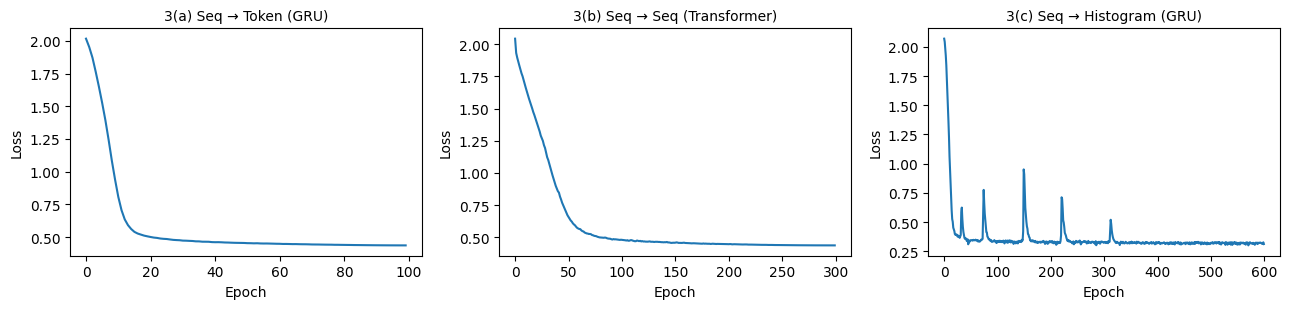

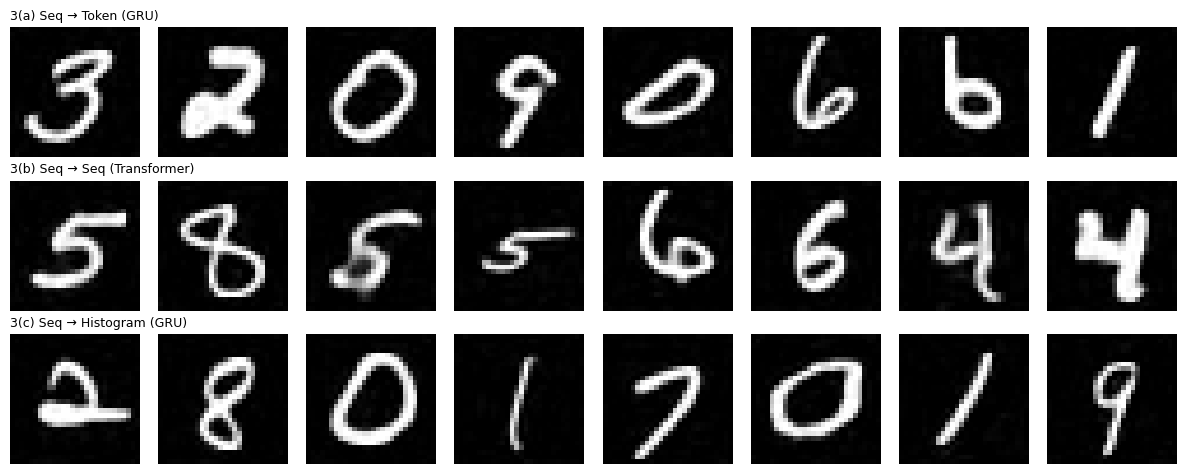

In [12]:
results = [("3(a) Seq → Token (GRU)", score_a, 80, samples_a),
           ("3(b) Seq → Seq (Transformer)", score_b, 80, samples_b),
           ("3(c) Seq → Histogram (GRU)", score_c, 99, samples_c)]

print(f"{'Model':28s} {'In train':>9s} {'Target':>7s} {'Distinct':>9s}  Status")
for name, score, target, s in results:
    distinct = len(set(map(tuple, s.tolist())))
    print(f"{name:28s} {score:8.1f}% {'>' + str(target) + '%':>7s} {distinct:9d}  "
          f"{'MET' if score > target else 'NOT MET'}")
print(f"\nImages used: {NUM_TRAIN} (3(c) requires > 512) | samples per model: {NUM_SAMPLES}")

# Loss curves
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (name, *_), losses in zip(axes, results, [loss_a, loss_b, loss_c]):
    ax.plot(losses); ax.set_title(name, fontsize=10); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
plt.tight_layout(); plt.savefig("p3_losses.png", dpi=120); plt.show()

# Decode 8 generated sequences from each model back into images
with torch.no_grad():
    fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
    for row, (name, _, _, s) in enumerate(results):
        imgs = ae.decoder(tokens_to_latent(s[:8]).to(device)).clamp(0, 1).cpu()
        for i in range(8):
            axes[row, i].imshow(imgs[i, 0], cmap="gray"); axes[row, i].axis("off")
        axes[row, 0].set_title(name, loc="left", fontsize=9)
plt.tight_layout(); plt.savefig("p3_generated.png", dpi=120); plt.show()

## Download results

In [ ]:
from google.colab import files
for name in ["tokens_1024.pt", "p3_losses.png", "p3_generated.png"]:
    files.download(name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>